# Reflectorch inference → Sisyphos-compliant NeXus/HDF5
**C60:DIP gradient thin film, 51 XRR positions**

This notebook runs reflectorch inference on every position of the C60:DIP gradient sample and saves everything (raw counts, processed curves, fitted parameters, prior bounds, model config, sample/instrument/user metadata) into one NeXus/HDF5 file.

The structure follows the Sisyphos metadata layout: `entry → data / instrument / sample / process / users/user_0`, with provenance (program, version, model YAML, processing dates) stored inside the file. At the end, the NeXus file and the results plot are downloaded to your computer.

## 0. Install
Clones the reflectorch branch that contains the NeXus saver and installs it in editable mode.

In [11]:
!pip -q install gpytorch botorch nflows chainconsumer spec2nexus h5py

%cd /content
!rm -rf /content/reflectorch /content/reflectorch_repo
!git clone -b reflectorch_sh https://github.com/schreiber-lab/reflectorch.git /content/reflectorch_repo
!pip -q install -e /content/reflectorch_repo

/content
Cloning into '/content/reflectorch_repo'...
remote: Enumerating objects: 5009, done.
remote: Counting objects: 100% (619/619), done.
remote: Compressing objects: 100% (390/390), done.
remote: Total 5009 (delta 399), reused 326 (delta 227), pack-reused 4390 (from 2)
Receiving objects: 100% (5009/5009), 272.01 MiB | 27.16 MiB/s, done.
Resolving deltas: 100% (3494/3494), done.
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for reflectorch (pyproject.toml) ... done


## 1. The NeXus saver
The saver lives in `reflectorch/inference/reflectorch_nexus_saver.py` and is imported from the package.

- `write_reflectorch_nexus(...)` writes the whole Sisyphos-compliant file.
- `add_reflectorch_output(...)` appends the full reflectorch output (all parameters, curves, SLD profiles).
- `PARAM_SPECS` says which parameters go in the file, with names, units and bound names.

The notebook downloads the finished NeXus file and the plot at the end.

> If the import fails right after installing, restart the runtime once (Runtime → Restart session) and run from section 2.

## 2. Upload the data files
Skips the upload if the files are already there (e.g. after a re-run).

In [3]:
import os

SPEC_FILE = "240503_C60_DIP_grad.spec"
CSV_FILE  = "240503_C60_DIP_XRR_profiles.csv"

missing = [f for f in (SPEC_FILE, CSV_FILE) if not os.path.exists(f)]
if missing:
    from google.colab import files
    print("Please upload:", missing)
    files.upload()

for f in (SPEC_FILE, CSV_FILE):
    print(f"{f:40s}", "OK" if os.path.exists(f) else "MISSING")

240503_C60_DIP_grad.spec                 OK
240503_C60_DIP_XRR_profiles.csv          OK


## 3. Configuration

In [1]:
import re, numpy as np, pandas as pd, torch, h5py
import matplotlib.pyplot as plt
from spec2nexus import spec
from reflectorch import InferenceModel
from reflectorch.inference import write_reflectorch_nexus, add_reflectorch_output

OUTPUT_H5   = "xrr_C60_DIP_multiscan_sisyphos.h5"
CONFIG_NAME = "g_mc_point_xray_intconv_standard_L1_InputQ_size1024"
DEVICE      = "cuda" if torch.cuda.is_available() else "cpu"
WAVELENGTH  = 1.5405452421779864   # Angstrom
TRIM_POINTS = 10                   # low-angle points removed in the reduction
SETUP_SCANS = {9, 15, 80}          # alignment scans

# prior bounds per model parameter, SLDs in 1e-6 A^-2
PRIOR_BOUNDS = {
    "Thickness L1": (150, 350),   "Roughness L1": (0, 55),   "Roughness sub": (0, 10),
    "SLD L1": (9, 14),            "SLD sub": (19.5, 20.5),
    "q_shift": (-0.002, 0.002),   "r_scale": (0.9, 1.1),
}
LABEL_TO_SCHEMA = {"Thickness L1": "thick", "Roughness L1": "rough", "SLD L1": "SLD",
                   "Roughness sub": "Si_rough", "r_scale": "r_scale", "q_shift": "q_shift"}

# metadata -> entry/users/user_0
USER_INFO = {
    "name":        "Shreya Shah",
    "ORCID":       "0000-0000-0000-0000",          # fill in
    "email":       "shreya.shah@uni-tuebingen.de",
    "affiliation": "University of Tübingen",
    "address":     "Auf der Morgenstelle 10, 72076 Tübingen, Germany",
    "role":        "",
}
# metadata -> entry/instrument/source/notes
BEAMTIME_INFO = {
    "principal_investigator": "Shreya Shah",
    "proposal_id": "Unknown",
    "DOI":         "Unknown",
    "beamtime_id": "",
}

/content/reflectorch_repo/reflectorch/data_generation/noise.py:132: SyntaxWarning: invalid escape sequence '\e'
  """Noise generator which applies noise as :math:`R_n = R * b^{\epsilon}` , where :math:`b` is a base and :math:`\epsilon` is sampled from the normal distribution :math:`\epsilon \sim \mathcal{N}(0, std)` .
/content/reflectorch_repo/reflectorch/data_generation/scale_curves.py:21: SyntaxWarning: invalid escape sequence '\l'
  :math:`\log_{10}(R + eps) \cdot weight + bias`.


## 4. Load data
Processed curves from the CSV, raw counts and motor positions from the SPEC file.

In [4]:
R_all = np.loadtxt(CSV_FILE, delimiter=",")[:, 1:].T          # (51, 91)
n_scans, n_q = R_all.shape

sp = spec.SpecDataFile(SPEC_FILE)
scan_nums = sorted(int(s.scanNum) for s in sp.scans.values()
                   if re.search(r"a2scan\s+th 0 1\s+tth 0 1\s+100", s.scanCmd)
                   and int(s.scanNum) not in SETUP_SCANS)
scans = [sp.getScan(n) for n in scan_nums]

raw_I     = np.vstack([np.array(s.data["Specular"])[TRIM_POINTS:] for s in scans])
two_theta = np.vstack([(np.array(s.data["Theta"]) + np.array(s.data["Two Theta"]))[TRIM_POINTS:] for s in scans])
y_motor   = np.array([float(s.positioner["Y"]) for s in scans])

assert len(scans) == n_scans, f"{len(scans)} SPEC scans != {n_scans} CSV curves"
assert raw_I.shape[1] == n_q, f"SPEC points {raw_I.shape[1]} != CSV q-points {n_q}"

q        = 4 * np.pi / WAVELENGTH * np.sin(np.deg2rad(two_theta[0] / 2))
dR_all   = R_all / np.sqrt(raw_I)
coord    = y_motor[::-1].copy()                                    # sample coordinate [mm]
frac_C60 = (coord - coord.min()) / (coord.max() - coord.min())     # linear gradient
print(f"{n_scans} curves x {n_q} points, coord {coord[0]:+.1f} ... {coord[-1]:+.1f} mm")

51 curves x 91 points, coord +27.5 ... -22.5 mm


## 5. Run inference
Predict + polish for every position. If polishing fails for a curve, the prediction is kept and polished values stay NaN.

In [6]:
model  = InferenceModel(config_name=CONFIG_NAME, device=DEVICE)
labels = model.trainer.loader.prior_sampler.param_model.get_param_labels()
prior_bounds = [PRIOR_BOUNDS[l] for l in labels]

nan = lambda *s: np.full(s, np.nan)
out = dict(predicted_params=nan(n_scans, len(labels)), polished_params=nan(n_scans, len(labels)),
           polished_params_error=nan(n_scans, len(labels)),
           predicted_curve=nan(n_scans, n_q), polished_curve=nan(n_scans, n_q),
           sld_xaxis=[], predicted_sld_profile=[], polished_sld_profile=[])

for i in range(n_scans):
    kw = dict(reflectivity_curve=R_all[i], q_values=q, sigmas=dR_all[i], prior_bounds=prior_bounds,
              use_sigmas_for_polishing=True, calc_pred_curve=True, calc_pred_sld_profile=True)
    try:
        d = model.preprocess_and_predict(polish_prediction=True, calc_polished_sld_profile=True, **kw)
    except RuntimeError:
        print(f"scan {i + 1}: polishing failed -> prediction only")
        d = model.preprocess_and_predict(polish_prediction=False, **kw)
    out["predicted_params"][i] = d["predicted_params_array"]
    out["predicted_curve"][i]  = np.interp(q, d["q_plot_pred"], d["predicted_curve"], left=np.nan, right=np.nan)
    out["sld_xaxis"].append(d["predicted_sld_xaxis"])
    out["predicted_sld_profile"].append(d["predicted_sld_profile"])
    out["polished_sld_profile"].append(d.get("sld_profile_polished", np.full_like(d["predicted_sld_profile"], np.nan)))
    if "polished_params_array" in d:
        out["polished_params"][i]       = d["polished_params_array"]
        out["polished_params_error"][i] = d["polished_params_error_array"]
        out["polished_curve"][i]        = d["polished_curve"]
for k in ("sld_xaxis", "predicted_sld_profile", "polished_sld_profile"):
    out[k] = np.vstack(out[k])

table = pd.DataFrame({"coord [mm]": coord})
for j, l in enumerate(labels):
    table[f"{l} pred"], table[f"{l} pol"] = out["predicted_params"][:, j], out["polished_params"][:, j]
table.round(3)

Configuration file `/content/reflectorch_repo/configs/g_mc_point_xray_intconv_standard_L1_InputQ_size1024.yaml` not found locally.


Weights file `/content/reflectorch_repo/saved_models/model_g_mc_point_xray_intconv_standard_L1_InputQ_size1024.safetensors` not found locally.
Model g_mc_point_xray_intconv_standard_L1_InputQ_size1024 loaded. Number of parameters: 21.88 M
The model corresponds to a `standard_model` parameterization with 1 layers (7 predicted parameters)
Parameter types and total ranges:
- thicknesses: [1.0, 500.0]
- roughnesses: [0.0, 60.0]
- slds: [0.0, 50.0]
- q_shift: [-0.002, 0.002]
- r_scale: [0.9, 1.1]
Allowed widths of the prior bound intervals (max-min):
- thicknesses: [0.01, 500.0]
- roughnesses: [0.01, 60.0]
- slds: [0.01, 5.0]
- q_shift: [1e-05, 0.004]
- r_scale: [0.001, 0.2]
The following quantities are additional inputs to the network: prior bounds.


,coord [mm],Thickness L1 pred,Thickness L1 pol,Roughness L1 pred,Roughness L1 pol,Roughness sub pred,Roughness sub pol,SLD L1 pred,SLD L1 pol,SLD sub pred,SLD sub pol,q_shift pred,q_shift pol,r_scale pred,r_scale pol
0,27.503,205.753,208.597,12.315,13.563,8.444,4.175,13.348,13.929,20.082,20.500,0.000,-0.000,0.928,0.909
1,26.504,205.740,208.962,12.293,13.306,8.167,3.965,13.281,13.910,20.117,20.500,0.000,-0.000,0.936,0.918
2,25.577,205.233,208.170,12.668,13.423,7.688,4.278,13.364,13.898,20.104,20.500,0.000,0.000,0.927,0.905
3,24.575,203.974,207.442,12.299,13.046,7.411,3.973,13.357,13.933,20.109,20.500,0.000,0.000,0.934,0.913
4,23.571,204.859,207.962,11.260,11.927,6.785,3.497,13.394,13.911,20.137,20.500,0.000,0.000,0.936,0.918
5,22.569,207.116,209.691,10.070,10.381,6.116,3.756,13.519,13.904,20.199,20.500,0.000,-0.000,0.935,0.918
6,21.565,210.038,212.491,9.167,8.705,5.696,4.718,13.644,13.927,20.211,20.500,0.000,0.000,0.949,0.923
7,20.562,212.034,215.303,8.180,7.652,4.614,3.861,13.698,13.953,20.234,20.500,0.000,-0.000,0.948,0.922
8,19.559,213.544,217.722,7.799,7.397,4.603,3.504,13.649,13.972,20.244,20.500,0.000,0.000,0.953,0.925
9,18.557,216.779,220.112,7.977,7.538,4.991,3.942,13.574,13.894,20.227,20.500,0.000,-0.000,0.945,0.923


## 6. Write the Sisyphos NeXus file
The first call writes the file, the second adds the full reflectorch output. Then the finished NeXus file is downloaded.

In [7]:
idx = {LABEL_TO_SCHEMA[l]: j for j, l in enumerate(labels) if l in LABEL_TO_SCHEMA}

write_reflectorch_nexus(
    OUTPUT_H5, q=q, R=R_all, dR=dR_all, coord=coord,
    predicted={n: out["predicted_params"][:, j] for n, j in idx.items()},
    polished={n: out["polished_params"][:, j] for n, j in idx.items()},
    prior_bounds={LABEL_TO_SCHEMA[l]: PRIOR_BOUNDS[l] for l in LABEL_TO_SCHEMA},
    model_yaml=(model.config_dir / model.config_name).read_text(),
    material_names=("C60", "DIP"), fractions=np.column_stack([frac_C60, 1 - frac_C60]),
    raw_intensity=raw_I, two_theta=two_theta, y_motor=y_motor,
    scan_numbers=scan_nums, timestamps=[s.date for s in scans], filename=SPEC_FILE,
    user_info=USER_INFO,
    instrument_info={"notes": BEAMTIME_INFO},
    download=False,                      # download once, after the next line
)
add_reflectorch_output(OUTPUT_H5, {"param_names": labels, "prior_bounds": np.array(prior_bounds), "q": q, **out},
                       download=False)

from google.colab import files
files.download(OUTPUT_H5)               # NeXus file -> your computer

NeXus file written -> /content/xrr_C60_DIP_multiscan_sisyphos.h5 [entry_0000] (51 scans x 91 q-points, 6 parameters)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 7. Check the Sisyphos fields

In [8]:
with h5py.File(OUTPUT_H5, "r") as f:
    e = f["entry_0000"]
    for p in ["users/user_0/name", "users/user_0/ORCID",
              "instrument/source/notes/principal_investigator",
              "instrument/techniques/technique_0/name",
              "instrument/monochromator/wavelength",
              "process/reflectorch/date", "process/footprint_correction/date"]:
        v = e[p][()]
        print(f"{p:50s} {v.decode() if isinstance(v, bytes) else v}")
    print("angle_of_incidence removed:", "instrument/angle_of_incidence" not in e)

users/user_0/name                                  Shreya Shah
users/user_0/ORCID                                 0000-0000-0000-0000
instrument/source/notes/principal_investigator     Shreya Shah
instrument/techniques/technique_0/name             X-Ray Reflectometry
instrument/monochromator/wavelength                1.5405452421779865e-10
process/reflectorch/date                           2026-11-10T16:12:16
process/footprint_correction/date                  2026-11-10T16:12:16
angle_of_incidence removed: True


## 8. Plot the results
Thickness, roughness and SLD across the gradient (predicted vs polished). The plot is also saved as PNG and downloaded.

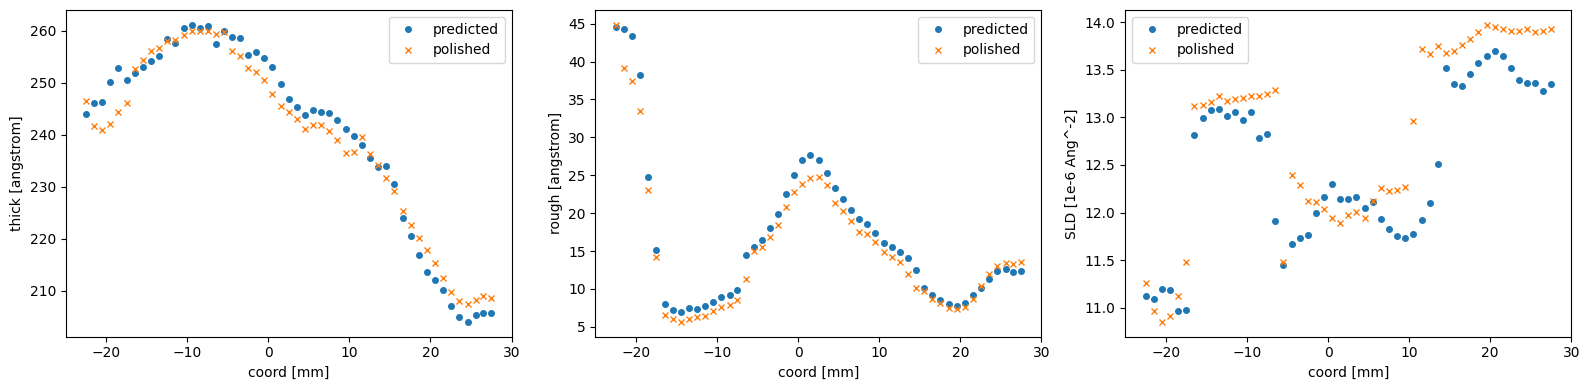

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:
with h5py.File(OUTPUT_H5, "r") as f:
    a = f["entry_0000/data/analysis"]
    c = a["coord"][:]
    res   = {n: a[n][:] for n in ("thick", "rough", "SLD")}
    units = {n: a[n].attrs["units"] for n in res}

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, n in zip(axes, res):
    ax.plot(c, res[n]["Predicted"], "o", ms=4, label="predicted")
    ax.plot(c, res[n]["Polished"], "x", ms=5, label="polished")
    ax.set_xlabel("coord [mm]"); ax.set_ylabel(f"{n} [{units[n]}]"); ax.legend()
plt.tight_layout()
fig.savefig("C60_DIP_reflectorch_results.png", dpi=200)
plt.show()

files.download("C60_DIP_reflectorch_results.png")